# Diabetic retinopathy model: predicting for a patient

The model has two stages:

1. A **vision model** (ResNet50, `model.h5`) grades the retina image and outputs a probability for each of the five grades.
2. A **random forest** (`models/stacker_rf.joblib`) combines these probabilities with **patient data** into the final grade.

`retinopathy_model.py` contains the code to load and run both stages. Download `model.h5` and the `images`
folder from the Google Drive folder linked in the README and adjust the paths below if needed.

In [1]:
import matplotlib.pyplot as plt

from retinopathy_model import GRADES, RetinopathyModel, load_image, load_patient

CNN_PATH = "model.h5"                       # vision model, from Google Drive
STACKER_PATH = "models/stacker_rf.joblib"   # random forest, in this repository
IMAGE_DIR = "images"                        # retina images, from Google Drive

model = RetinopathyModel(CNN_PATH, STACKER_PATH)

## Patient data

Each patient has an id, which is also the name of their retina image. `load_patient` looks up the
patient data in `data/train.csv` and `data/test.csv`.

In [2]:
patient = load_patient("281d7b7c7676")

print(f"patient:          {patient.id_code}")
print(f"age:              {patient.age}")
print(f"gender:           {'male' if patient.gender == 'M' else 'female'}")
print(f"diabetes:         type {patient.diabetes_type}, for {patient.diabetes_years} years")
print(f"HbA1c:            {patient.hba1c}%")
print(f"systolic BP:      {patient.systolic_bp} mmHg")

patient:          281d7b7c7676
age:              70
gender:           female
diabetes:         type 2, for 18 years
HbA1c:            9.0%
systolic BP:      149 mmHg


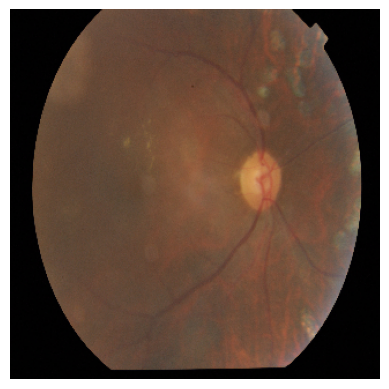

In [3]:
image = load_image(f"{IMAGE_DIR}/{patient.id_code}.png")
plt.imshow(image)
plt.axis("off")
plt.show()

## Prediction

In [4]:
prediction = model.predict(image, patient)

print(f"final grade:              {prediction.grade_name}")
print(f"grade from image alone:   {GRADES[prediction.cnn_grade]}")
print(f"grade by clinician:       {GRADES[patient.diagnosis]}")
print()
print(f"{'grade':18s} {'image alone':>12s} {'final':>8s}")
for grade, name in GRADES.items():
    print(f"{name:18s} {prediction.cnn_probabilities[grade]:12.2f} {prediction.probabilities[grade]:8.2f}")

final grade:              Proliferative DR
grade from image alone:   Moderate
grade by clinician:       Proliferative DR

grade               image alone    final
No DR                      0.00     0.00
Mild                       0.16     0.10
Moderate                   0.76     0.39
Severe                     0.01     0.08
Proliferative DR           0.07     0.42
